<a href="https://colab.research.google.com/github/Sanjay-H-02/DAV_lab/blob/main/Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.decomposition import PCA
print("Libraries imported successfully")
#

Libraries imported successfully


In [ ]:
data = pd.DataFrame({
    "Study_hours": [2,4,5,7,8,10],
    "Attendence_per":[50,60,65,75,85,95],
    "Assignment_scores":[35,45,55,65,80,95],
    "Total_marks": [38,48,56,68,82,94]

    })

In [ ]:
data

,Study_hours,Attendence_per,Assignment_scores,Total_marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [ ]:
features = data[["Study_hours","Attendence_per","Assignment_scores","Total_marks"]]
print(features.min())
print(features.max())

Study_hours           2
Attendence_per       50
Assignment_scores    35
Total_marks          38
dtype: int64
Study_hours          10
Attendence_per       95
Assignment_scores    95
Total_marks          94
dtype: int64


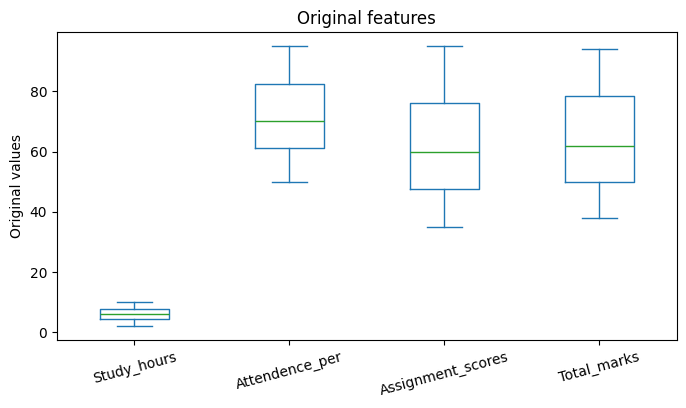

In [ ]:
features.plot(kind="box",figsize=(8,4))
plt.title("Original features")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
normalizer = MinMaxScaler()
normalized_array = normalizer.fit_transform(features)
normalized_df = pd.DataFrame(normalized_array,columns=features.columns,index=features.index)
display(normalized_df.round(3))


,Study_hours,Attendence_per,Assignment_scores,Total_marks
0,0.000,0.000,0.000,0.000
1,0.250,0.222,0.167,0.179
2,0.375,0.333,0.333,0.321
3,0.625,0.556,0.500,0.536
4,0.750,0.778,0.750,0.786
5,1.000,1.000,1.000,1.000


In [ ]:
print("Minimum after normalisation")
print(normalized_df.min())
print("Maximum after normalisation")
print(normalized_df.max())

Minimum after normalisation
Study_hours          0.0
Attendence_per       0.0
Assignment_scores    0.0
Total_marks          0.0
dtype: float64
Maximum after normalisation
Study_hours          1.0
Attendence_per       1.0
Assignment_scores    1.0
Total_marks          1.0
dtype: float64


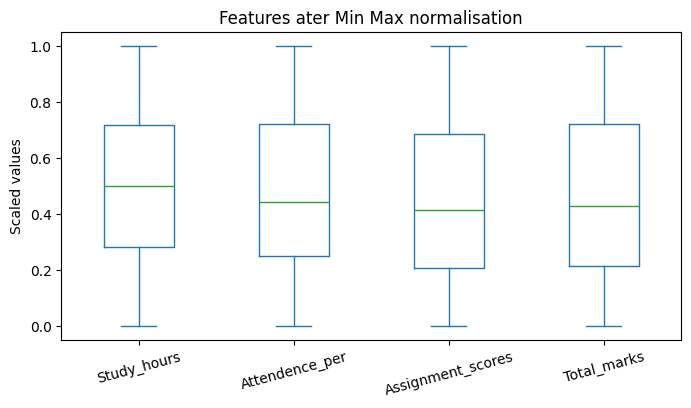

In [ ]:
normalized_df.plot(kind="box",figsize=(8,4))
plt.title("Features ater Min Max normalisation")
plt.ylabel("Scaled values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
standardizer = StandardScaler()
standardizer_array = standardizer.fit_transform(features)
standardizer_df = pd.DataFrame(standardizer_array,columns=features.columns,index=features.index)
display(standardizer_df.round(3))

,Study_hours,Attendence_per,Assignment_scores,Total_marks
0,-1.512,-1.427,-1.351,-1.364
1,-0.756,-0.768,-0.859,-0.846
2,-0.378,-0.439,-0.368,-0.432
3,0.378,0.220,0.123,0.190
4,0.756,0.878,0.859,0.915
5,1.512,1.537,1.596,1.537


In [ ]:
print("Mean after standardization")
print(standardizer_df.mean().round(6))
print("Standard deviation after standardization")
print(standardizer_df.std().round(6))

Mean after standardization
Study_hours          0.0
Attendence_per      -0.0
Assignment_scores    0.0
Total_marks          0.0
dtype: float64
Standard deviation after standardization
Study_hours          1.095445
Attendence_per       1.095445
Assignment_scores    1.095445
Total_marks          1.095445
dtype: float64


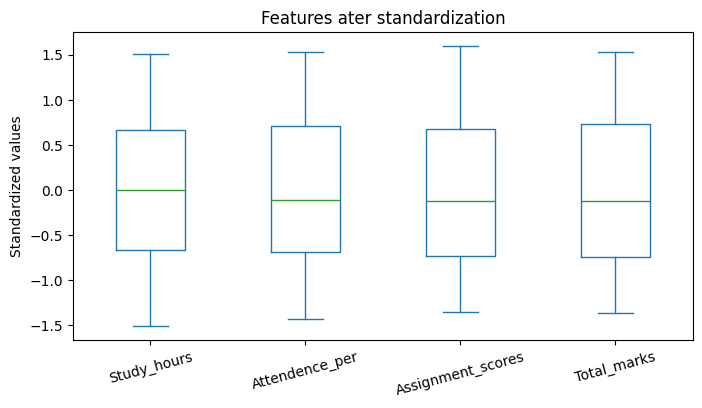

In [ ]:
standardizer_df.plot(kind="box",figsize=(8,4))
plt.title("Features ater standardization")
plt.ylabel("Standardized values")
plt.xticks(rotation=15)
plt.show()
#

In [ ]:
scaled_features = StandardScaler().fit_transform(features)
pca = PCA(n_components=2)
pca_array = pca.fit_transform(scaled_features)
pca_df = pd.DataFrame(pca_array,columns=["PC1","PC2"],index=features.index)
display(pca_df.round(3))

,PC1,PC2
0,-2.827,-0.129
1,-1.615,0.079
2,-0.809,0.011
3,0.455,0.186
4,1.705,-0.100
5,3.091,-0.046


In [ ]:
variance_ratios = pca.explained_variance_ratio_
for component, ratio in zip(["PC1","PC2"],variance_ratios):
    print(f"{component} explains {ratio:2%} of the variance")

total_retained = variance_ratios.sum()
print(f"Total variance retained: {total_retained:2%}")
#

PC1 explains 99.660723% of the variance
PC2 explains 0.290002% of the variance
Total variance retained: 99.950725%


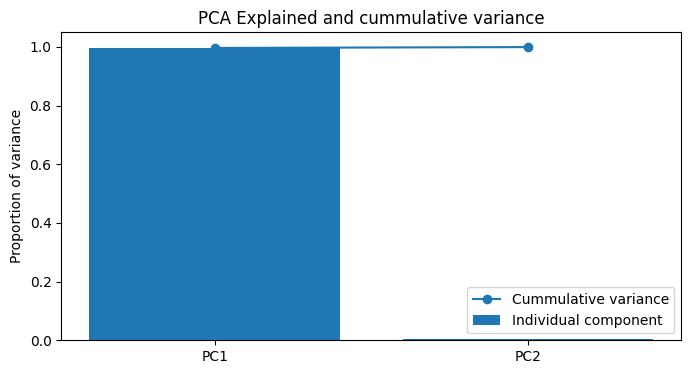

In [ ]:
component_names = ["PC1","PC2"]
cummulative_variance = variance_ratios.cumsum()

plt.figure(figsize=(8,4))
plt.bar(component_names, variance_ratios)
plt.plot(component_names, cummulative_variance, marker="o")
plt.ylim(0,1.05)
plt.ylabel("Proportion of variance")
plt.title("PCA Explained and cummulative variance")
plt.legend(["Cummulative variance","Individual component"])
plt.show()

In [ ]:
print("Number of orignal input features:",features.shape[1])
print("Number of principal components:",pca_df.shape[1])
print("Original feature shape:",features.shape)
print("Reduced pca data shape:",pca_df.shape)

Number of orignal input features: 4
Number of principal components: 2
Original feature shape: (6, 4)
Reduced pca data shape: (6, 2)
